# Validate against buoy observations

Compare **offshore hindcast** (closest goal node), **bulk metamodel**, **spectral metamodel**, and **dynamic SnapWave** to buoy records.

**Prerequisites**

1. Fitted models — `06_Validate_Metamodel.ipynb` (`mm.fit_all`)
2. Dynamic run for the same period — `08_Dynamic_Cases_Generation.ipynb`
3. Observations GeoJSON — `03_Generate_Observations_Configuration.ipynb` → `inputs/Observations/Samoa_observations.json`
4. Processed buoy file(s) under `inputs/Observations/processed/` (you build these in the notebook below)

Use the **same `period`** for buoy data, reconstruction, and dynamic output.

Comparisons request **`hs`, `tp`, `dir`, and `spr`**. Variables missing from the buoy
file or any model are skipped automatically.

In [1]:
import matplotlib.pyplot as plt
import xarray as xr
from utils.config import SIMULATIONS, resolve
from utils.evaluation import validation as val
from utils.model import metamodel as mm
from utils.observation import onshore_sites as obs

## Configuration

Pick buoy sites from the observations GeoJSON (`instrument_id` keys). SnapWave site
labels are `buoy_{instrument_id}`. Point each site to its processed NetCDF (bulk or
spectral) under `inputs/Observations/processed/`.

In [2]:
period = "2020-01"  # e.g. "1990-05" or "2020-05" — must match buoy + dynamic
offshore_name = "WHACS"
mda_n = 450
pca_variance = {"hs": 0.99, "dir": 0.99}

# SnapWave site labels (mesh / reconstruction ids)
sites = ["buoy_Aunuu_Buoy"]

# Metrics to request (subset used when missing from buoy or any model)
requested_variables = ["hs", "tp", "dir", "spr"]

dynamic_path = (
    resolve(SIMULATIONS["dynamic_cases"]) / f"Dynamic_Cases_{offshore_name}_2020.nc"
)

print("Observations JSON:", obs.geojson_path())
print(f"period         : {period}")
print(f"mda_n          : {mda_n}")
print(f"sites          : {sites}")
print(f"requested vars : {requested_variables}")
print(f"dynamic path   : {dynamic_path}")
print(f"dynamic exists : {dynamic_path.is_file()}")

Observations JSON: /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/Observations/Samoa_observations.json
period         : 2020-01
mda_n          : 450
sites          : ['buoy_Aunuu_Buoy']
requested vars : ['hs', 'tp', 'dir', 'spr']
dynamic path   : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Dynamic/Dynamic_Cases_WHACS_2020.nc
dynamic exists : True


## 1 · Check models

In [3]:
mm.require_models_all(mda_n, pca_variance=pca_variance)

## 2 · Process buoy observations

Load each processed file, rename variables to HyGloW names (`hs`, `tp`, `dir`, `spr`),
slice to `period`, and build a validation dataset on `(time, sites)` with CF-style
attributes. Site metadata (lon/lat/depth) comes from the observations GeoJSON.

In [4]:
buoy = (
    xr.open_dataset("inputs/Observations/processed/buoy_Anuu_with_spectra.nc")
    .sel(time=period)
    .Efth.spec.stats(["hs", "tp", "dm", "dspr"])
    .load()
    .rename({"dm": "dir", "dspr": "spr"})
    .expand_dims(sites=["buoy_Aunuu_Buoy"])
    .transpose("time", "sites")
)
buoy

<xarray.Dataset> Size: 27kB
Dimensions:  (sites: 1, time: 744)
Coordinates:
  * sites    (sites) object 8B 'buoy_Aunuu_Buoy'
  * time     (time) datetime64[ns] 6kB 2020-01-01 ... 2020-01-31T23:00:00
Data variables:
    hs       (time, sites) float64 6kB 2.323 2.424 2.555 ... 2.05 1.867 1.867
    tp       (time, sites) float32 3kB 9.365 8.679 9.838 ... 15.17 8.769 8.769
    dir      (time, sites) float64 6kB 286.0 305.4 301.6 ... 90.11 132.8 132.8
    spr      (time, sites) float64 6kB 63.75 59.44 59.11 ... 73.73 69.91 69.91
Attributes:
    standard_name:  sea_surface_wave_significant_height
    units:          m

## 3 · Reconstruct metamodel, load dynamic, and closest-goal offshore hindcast

Metamodel bulk/spectral reconstructions, dynamic SnapWave, and bulk offshore forcing
at each buoy's **closest goal hindcast node** (all sources in ``Samoa.json`` —
currently WHACS only).

In [5]:
bulk = mm.reconstruct(
    period,
    mda_n,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
)

spectral = mm.reconstruct(
    period,
    mda_n,
    spectral=True,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
)

if not dynamic_path.is_file():
    raise FileNotFoundError(
        f"Dynamic output not found: {dynamic_path}\n"
        "Run 08_Dynamic_Cases_Generation for this period or change `period`."
    )

dynamic = xr.open_dataset(dynamic_path).sel(time=period)
site_ids = mm.resolve_reconstruction_sites(dynamic, sites)
dynamic = dynamic.sel(sites=site_ids).load()

offshore_hindcast, closest_goals = val.load_offshore_hindcast_at_buoys(
    period,
    sites,
    variables=requested_variables,
)
closest_goals

estimates = {
    **offshore_hindcast,
    "Bulk metamodel": bulk,
    "Spectral metamodel": spectral,
    "Dynamic SnapWave": dynamic,
}

variables = val.resolve_comparison_variables(
    buoy,
    *estimates.values(),
    variables=requested_variables,
)
print(f"Comparing: {variables}")

2026-07-14 11:33:22,731 - hyglow.metamodel - INFO - Loading reconstruction cache: reconstruct-v4__reconstruct__offshore-WHACS__n-450__bulk__goals-all__wl-0__sites-buoy_Aunuu_Buoy__vars-dir-dm-hs-hs-spr-dspr-tp-tp__pca-dir0.99_hs0.99__cfg-b6ae470f__time-2020-01.nc
2026-07-14 11:33:23,035 - hyglow.metamodel - INFO - Loading reconstruction cache: reconstruct-v4__reconstruct__offshore-WHACS__n-450__spectral__goals-all__wl-0__sites-buoy_Aunuu_Buoy__vars-dir-dm-hs-hs-spr-dspr-tp-tp__pca-dir0.99_hs0.99__cfg-b6ae470f__time-2020-01.nc
2026-07-14 11:33:23,577 - hyglow.validation - INFO - Offshore WHACS: 1 site(s) mapped to goals [8]


Comparing: ['hs', 'tp', 'dir', 'spr']


## 4 · Metrics vs buoy

In [6]:
results = val.compare_all(
    buoy,
    estimates,
    sites=sites,
    variables=variables,
    reference_label="Buoy",
)

summary = val.metrics_summary(results)
summary

2026-07-14 11:33:23,592 - hyglow.validation - INFO - Computed 4 validation metric row(s)


2026-07-14 11:33:23,601 - hyglow.validation - INFO - Computed 4 validation metric row(s)
2026-07-14 11:33:23,608 - hyglow.validation - INFO - Computed 4 validation metric row(s)
2026-07-14 11:33:23,616 - hyglow.validation - INFO - Computed 4 validation metric row(s)


,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label,model
0,buoy_Aunuu_Buoy,buoy,waves,hs,Hs,744,-0.286776,0.387966,0.409939,WHACS (closest goal),Buoy,WHACS (closest goal)
1,buoy_Aunuu_Buoy,buoy,waves,tp,Tp,744,1.054112,2.814835,-0.113896,WHACS (closest goal),Buoy,WHACS (closest goal)
2,buoy_Aunuu_Buoy,buoy,waves,dir,Dir,744,-9.759605,42.403895,0.631323,WHACS (closest goal),Buoy,WHACS (closest goal)
3,buoy_Aunuu_Buoy,buoy,waves,spr,Spr,744,0.897324,5.440846,0.384377,WHACS (closest goal),Buoy,WHACS (closest goal)
4,buoy_Aunuu_Buoy,buoy,waves,hs,Hs,744,-0.605617,0.734030,-1.610804,Bulk metamodel,Buoy,Bulk metamodel
5,buoy_Aunuu_Buoy,buoy,waves,tp,Tp,744,0.614683,2.300909,0.030569,Bulk metamodel,Buoy,Bulk metamodel
6,buoy_Aunuu_Buoy,buoy,waves,dir,Dir,744,-2.016866,38.026257,0.703516,Bulk metamodel,Buoy,Bulk metamodel
7,buoy_Aunuu_Buoy,buoy,waves,spr,Spr,744,-17.393159,21.120532,-2.114837,Bulk metamodel,Buoy,Bulk metamodel
8,buoy_Aunuu_Buoy,buoy,waves,hs,Hs,744,-0.450323,0.552210,-0.679901,Spectral metamodel,Buoy,Spectral metamodel
9,buoy_Aunuu_Buoy,buoy,waves,tp,Tp,744,-1.050500,2.209256,0.249714,Spectral metamodel,Buoy,Spectral metamodel


## 5 · Scatter plots

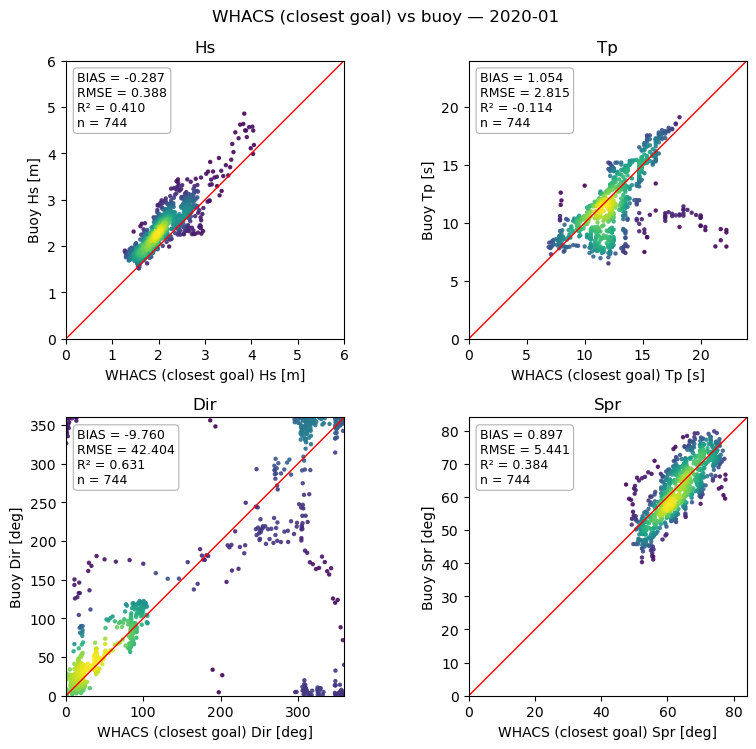

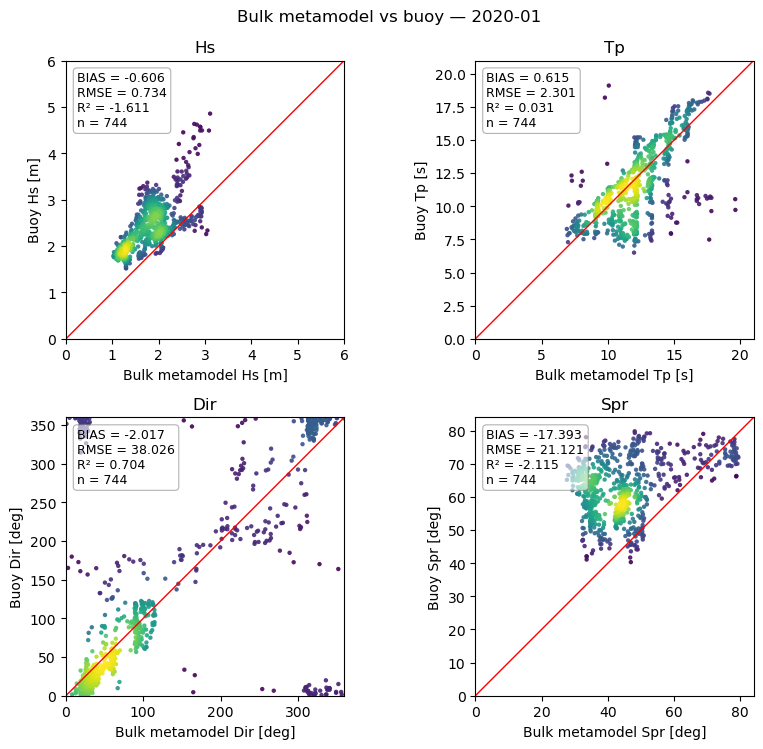

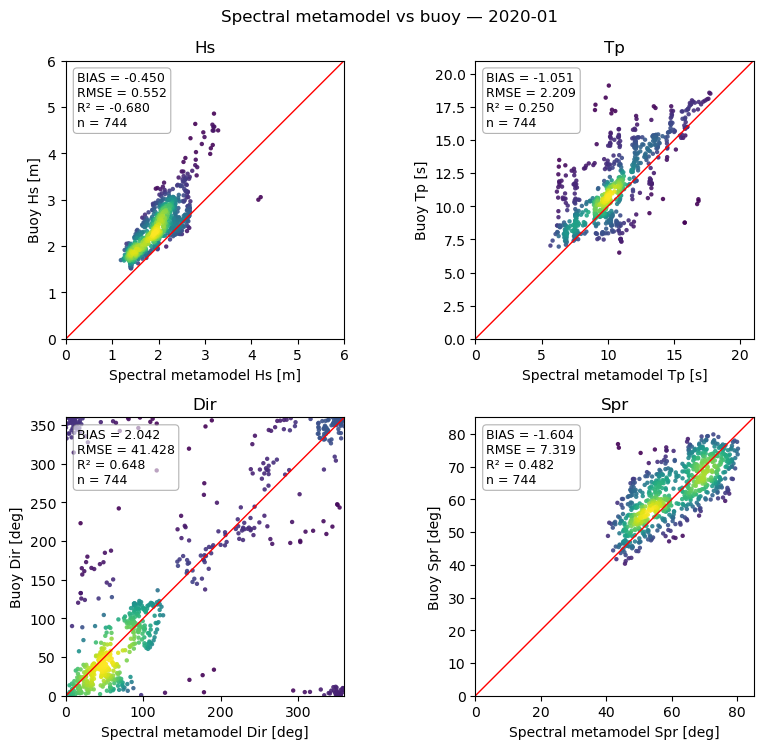

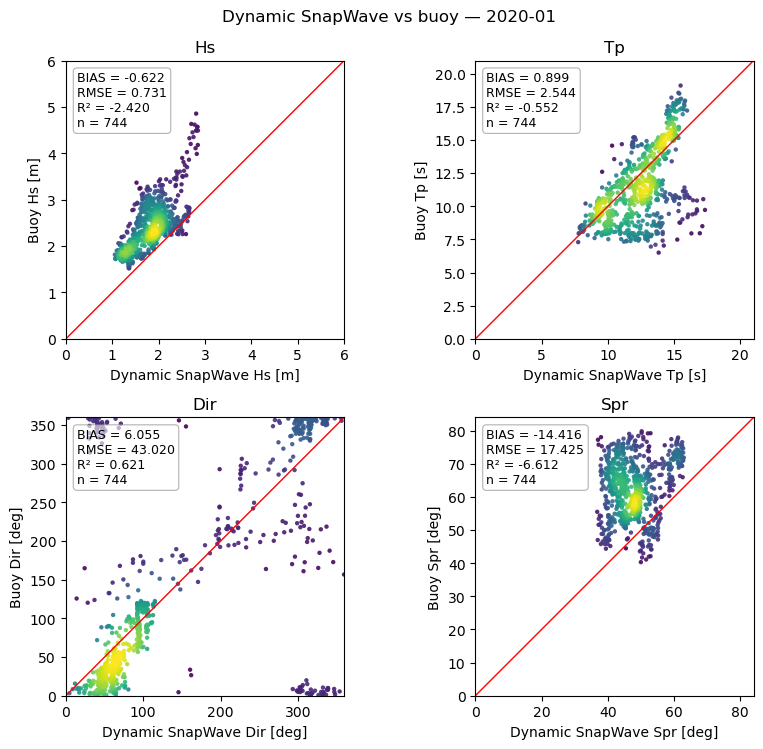

In [7]:
group = mm.resolve_sites(estimates["Bulk metamodel"], sites)[0]

for name, result in results.items():
    result.plot_scatter(
        group,
        variables=variables,
        estimate_label=name,
        reference_label="Buoy",
    )
    plt.suptitle(f"{name} vs buoy — {period}")
    plt.show()

## 6 · Time series

Line plots of buoy observations vs each model over the validation period (direction as scatter).

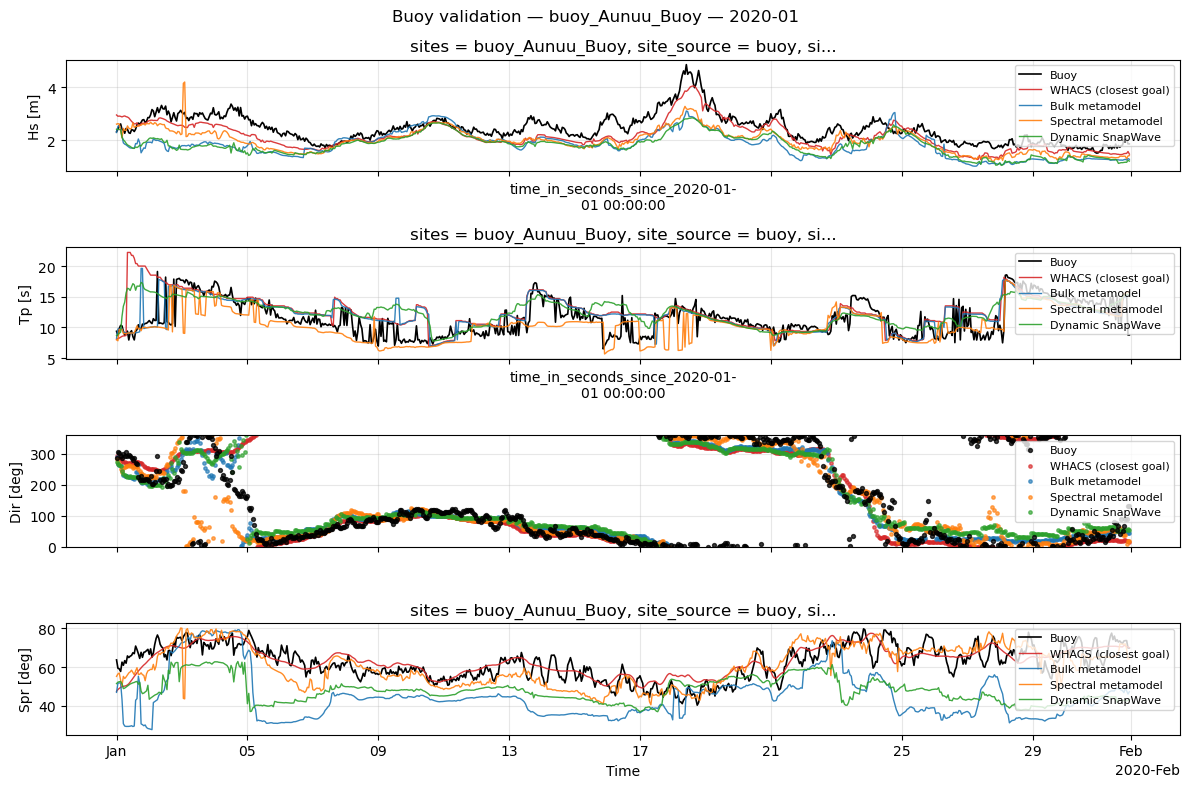

In [8]:
for site in sites:
    val.plot_buoy_timeseries(buoy, estimates, site, variables=variables)
    plt.suptitle(f"Buoy validation — {site} — {period}")
    plt.show()